# fNIRS / DOT group analysis

Cedalion per-subject preprocessing → DOT image reconstruction (Brodmann atlas) →
signal quality, FPA ROI responses and effect maps.

## 0 · Configuration

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from cedalion import units

from processors_cedalion.plotstyle import set_publication_style
from processors_cedalion.processing import *
from processors_cedalion.visualization import *
from processors_cedalion.bids_loader import build_bids_manifest, iter_bids_recordings
from processors_cedalion.atlas_brodmann import (
    assign_brodmann_to_head, relabel_image_parcels,
    available_parcels_from_image, select_roi_parcels, BRODMANN_ROIS,
)
from processors_cedalion import quality_metrics as qm
from processors_cedalion import roi_analysis as roi

set_publication_style()

# --- data: NIRS-BIDS dataset (OpenNeuro ds008544); point BIDS_ROOT at your copy
BIDS_ROOT           = r"C:/Users/Robert Kwaśniak/Desktop/Desktop files/2026 Dataset NeuroPhotonics/Data revisited/3 STUDY"
BIDS_TASK           = None      # None = all tasks
BIDS_CONDITION_FROM = "task"    # BIDS entity holding SITTING/WALKING

# --- head model and precomputed forward model (outside git) ---
HEAD_MODEL       = "colin27"    # "icbm152" | "colin27"
DATA_DIR         = r"C:/Vs code"
FLUENCE_FILE     = f"{DATA_DIR}/fluence_{HEAD_MODEL}.h5"
SENSITIVITY_FILE = f"{DATA_DIR}/sensitivity_{HEAD_MODEL}.h5"
PRECOMPUTED      = True         # False simulates fluence/sensitivity (again for every run:
                                #   set back to True once the files exist)
FLUENCE_METHOD   = "mcx"        # "mcx" | "nirfaster"

# --- image reconstruction ---
RECON_MODE    = "mua2conc"      # mua per wavelength, then HbO/HbR
ALPHA_MEAS    = 0.01            # measurement regularization
ALPHA_SPATIAL = 0.001           # spatial regularization

# --- experiment ---
EVENT_MAP   = {"1": "MC", "2": "REST"}
EPOCH_BEFORE, EPOCH_AFTER = 2.0, 17.0
RESP_WINDOW = (0, 17.0)         # averaging window (s)

# --- signal quality ---
SCI_WINDOW_S = 5.0             # SCI window (s): channel pruning and quality table

# --- ROIs (Brodmann areas: atlas_brodmann.BRODMANN_ROIS) ---
ROIS          = ("FPA",)
ATLAS_MNI_EPS = 5.0             # volumetric -> surface labelling radius

SESSION_TO_CONDITION = {
    "sit": "SITTING", "sitting": "SITTING",
    "walk": "WALKING", "walking": "WALKING",
}
CONDITION_ORDER = ["WALKING", "SITTING"]

RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figs"); FIG_DIR.mkdir(exist_ok=True)
print("Configuration loaded.")

Configuration loaded.


## 1 · Run manifest

One row per run (SNIRF file): subject, condition, demographics.

In [3]:
manifest = build_bids_manifest(
    BIDS_ROOT,
    condition_from=BIDS_CONDITION_FROM,
    condition_map=SESSION_TO_CONDITION,
    task_filter=BIDS_TASK,
)
manifest = manifest.rename(columns={"subject_label": "subject_id"})
# yields (run_id, rec, amp, meta)
def recording_iter():
    yield from iter_bids_recordings(manifest, add_events_from_tsv=True)

display(manifest.head(12))
print("runs per condition:\n", manifest["condition"].value_counts(dropna=False))

[bids] 78 run(s) across 39 subject(s) discovered in C:\Users\Robert Kwaśniak\Desktop\Desktop files\2026 Dataset NeuroPhotonics\Data revisited\3 STUDY
[bids] runs per condition:
        SITTING: 39
        WALKING: 39


,run_id,subject_id,participant_id,task,session,acq,run,snirf_path,condition,age,sex,hand,weight,height,group,ppf,gender
0,sub-01_ses-1_task-SITTING_nirs,01,sub-01,SITTING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,SITTING,42,NaN,NaN,NaN,NaN,1,6.0,male
1,sub-01_ses-1_task-WALKING_nirs,01,sub-01,WALKING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,WALKING,42,NaN,NaN,NaN,NaN,1,6.0,male
2,sub-02_ses-1_task-SITTING_nirs,02,sub-02,SITTING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,SITTING,24,NaN,NaN,NaN,NaN,1,6.0,male
3,sub-02_ses-1_task-WALKING_nirs,02,sub-02,WALKING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,WALKING,24,NaN,NaN,NaN,NaN,1,6.0,male
4,sub-03_ses-1_task-SITTING_nirs,03,sub-03,SITTING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,SITTING,20,NaN,NaN,NaN,NaN,1,6.0,male
5,sub-03_ses-1_task-WALKING_nirs,03,sub-03,WALKING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,WALKING,20,NaN,NaN,NaN,NaN,1,6.0,male
6,sub-04_ses-1_task-SITTING_nirs,04,sub-04,SITTING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,SITTING,37,NaN,NaN,NaN,NaN,1,6.0,male
7,sub-04_ses-1_task-WALKING_nirs,04,sub-04,WALKING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,WALKING,37,NaN,NaN,NaN,NaN,1,6.0,male
8,sub-05_ses-1_task-SITTING_nirs,05,sub-05,SITTING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,SITTING,29,NaN,NaN,NaN,NaN,1,6.0,male
9,sub-05_ses-1_task-WALKING_nirs,05,sub-05,WALKING,1,None,None,C:\Users\Robert Kwaśniak\Desktop\Desktop files...,WALKING,29,NaN,NaN,NaN,NaN,1,6.0,male


runs per condition:
 condition
SITTING    39
WALKING    39
Name: count, dtype: int64


## 2 · Per-subject pipeline

events → OD → SCI pruning → TDDR → band-pass 0.01–0.2 Hz → short-channel regression →
pruned channels dropped → epochs → block average → optode registration → forward model → image reconstruction
(`mua2conc`) → baseline correction → Brodmann labels. Head model and labels are
computed once.

In [4]:
head_ijk = load_head_model(HEAD_MODEL)
head_brod = assign_brodmann_to_head(head_ijk, mni_eps=ATLAS_MNI_EPS)

all_results = {}   # run_id -> dict

for run_id, rec, amp, meta in recording_iter():
    print(f"\n{'='*64}\nProcessing {run_id}  (condition={meta.get('condition')})\n{'='*64}")

    # events, OD
    rename_events(rec, EVENT_MAP)
    convert_to_od(rec, method="cedalion", nonpositive="abs_floor")

    # SCI pruning
    amp_pruned, drop_list = prune_channels(
        rec, snr_thresh=None, sci_thresh=0.75, sci_window=SCI_WINDOW_S * units.s,
        psp_thresh=None, sd_threshs=None, amp_threshs=None,
        perc_time_clean=0.5, operator="all")
    print(f"  pruned {len(drop_list)} channels")

    # motion, band-pass, short channels (pruned short channel -> mean of the surviving ones)
    correct_motion_tddr(rec, od_key="od")
    freq_filter(rec, input_key="od_tddr", fmin=0.01, fmax=0.2)
    try:
        rec["od_clean"], sc_info = short_channel_regression(
            rec, od_key="od_filtered", max_dist=10 * units.mm, bad_channels=drop_list)
        ts_key = "od_clean"
        print(f"  short channels kept: {sc_info['n_short_ok']}/{sc_info['n_short']}; "
              f"long channels on the short-channel mean: "
              f"{len(sc_info['long_mean_regressor'])}/{sc_info['n_long']}")
    except Exception as exc:
        ts_key, sc_info = "od_filtered", None
        print(f"  short-channel regression skipped ({exc}); using {ts_key}")

    # pruned channels out of epochs, block average and image reconstruction
    rec["od_used"] = drop_channels(rec[ts_key], drop_list)
    print(f"  channels in block average / reconstruction: {rec['od_used'].sizes['channel']}")

    # epochs, block average
    trial_types = list(rec.stim["trial_type"].unique())
    epochs = compute_epochs(rec, ts_key="od_used", trial_types=trial_types,
                            before=EPOCH_BEFORE, after=EPOCH_AFTER)
    blockavg = compute_block_average(epochs)

    # registration, forward model, sensitivity
    geo3d_snapped = register_optodes(head_ijk, rec.geo3d)
    fwm = create_forward_model(head_ijk, geo3d_snapped, rec._measurement_lists["amp"])
    compute_fluence(fwm, FLUENCE_FILE, method=FLUENCE_METHOD, precomputed=PRECOMPUTED)
    Adot = compute_sensitivity(fwm, FLUENCE_FILE, SENSITIVITY_FILE, precomputed=PRECOMPUTED)

    # image reconstruction, baseline, Brodmann labels
    img = run_image_reconstruction(Adot, blockavg, recon_mode=RECON_MODE,
                                   alpha_meas=ALPHA_MEAS, alpha_spatial=ALPHA_SPATIAL)
    img_brain_bl = relabel_image_parcels(baseline_correct_image(img), head_brod)

    all_results[run_id] = {
        "rec": rec, "amp": rec["amp"], "blockavg": blockavg,
        "Adot": Adot, "img_brain_bl": img_brain_bl,
        "drop_list": drop_list, "sc_info": sc_info, "geo3d_snapped": geo3d_snapped,
        "head_ijk": head_ijk, "fwm": fwm,
        **meta,
    }

print(f"\nDone. {len(all_results)} run(s) processed.")

[atlas] Brodmann assigned to 25000 vertices (86 areas, 1025 background). Increase mni_eps if background is high.

Processing sub-01_ses-1_task-SITTING_nirs  (condition=SITTING)
  [convert_to_od] abs_floor: repaired 1972 non-positive sample(s) (floor=3.815e-05 dimensionless)
  pruned 9 channels
  short channels kept: 3/3; long channels on the short-channel mean: 0/311
  channels in block average / reconstruction: 302
Using precomputed fluence: C:\Vs code\fluence_colin27.h5
Using precomputed sensitivity: C:\Vs code\sensitivity_colin27.h5

Processing sub-01_ses-1_task-WALKING_nirs  (condition=WALKING)
  [convert_to_od] abs_floor: repaired 2392 non-positive sample(s) (floor=3.815e-05 dimensionless)
  pruned 2 channels
  short channels kept: 3/3; long channels on the short-channel mean: 0/311
  channels in block average / reconstruction: 309
Using precomputed fluence: C:\Vs code\fluence_colin27.h5
Using precomputed sensitivity: C:\Vs code\sensitivity_colin27.h5

Processing sub-02_ses-1_task

---
# Signal quality (SNR, SCI, CV)

SNR, SCI and CV for every channel × wavelength of every run, then one value per
participant (median over the observations), split by condition: Table 1, the
SITTING vs WALKING tests and the signal-quality figure of the paper.

In [5]:
quality_df = qm.build_group_quality_table(
    all_results,
    condition_key="condition", subject_key="subject_id",
    sci_window_s=SCI_WINDOW_S, sci_thresh=0.75, snr_thresh=10.0, cv_thresh=15.0,
    output_path=RESULTS_DIR / "group_quality_metrics.csv",
)
summary = qm.summarize_group_quality(quality_df)
display(summary.round(3))
summary.to_csv(RESULTS_DIR / "group_quality_summary.csv", index=False)

[quality] group quality table: 48984 rows -> results\group_quality_metrics.csv


,condition,n_subjects,n_channel_obs,snr_mean,snr_sd,snr_q1,snr_median,snr_q3,snr_iqr,pct_snr_pass,...,sci_q3,sci_iqr,pct_sci_pass,cv_mean,cv_sd,cv_q1,cv_median,cv_q3,cv_iqr,pct_cv_pass
0,SITTING,39,24492,36.962,608.000,12.127,22.943,38.55,26.423,80.602,...,0.986,0.187,77.666,19.573,1387.824,2.507,4.220,7.859,5.352,88.845
1,WALKING,39,24492,24.558,32.303,11.819,19.814,32.11,20.291,81.006,...,0.994,0.074,85.595,19.655,2072.933,3.011,4.918,8.159,5.148,90.344


In [6]:
# one value per participant: median (and mean) over all channel × wavelength observations
subj = qm.summarize_subject_quality(quality_df)
subj.to_csv(RESULTS_DIR / "subject_quality_summary.csv", index=False)
wide = qm.pivot_subject_quality(subj, conditions=["SITTING", "WALKING"])
wide.to_csv(RESULTS_DIR / "subject_quality_wide.csv", index=False)
print(f"[quality] {len(wide)} participants -> subject_quality_summary.csv, subject_quality_wide.csv")

[quality] 39 participants -> subject_quality_summary.csv, subject_quality_wide.csv


In [7]:
# Table 1: Md, Q1, Q3 of the participant medians; % pass = mean of the participant
# percentages. Tests on the participant medians: Shapiro-Wilk on SITTING - WALKING,
# Wilcoxon signed-rank (z with tie correction, rank-biserial r).
from scipy import stats

QUALITY_LABEL = {"snr": "SNR", "sci": "SCI", "cv": "CV (%)"}
DEC = {"snr": 2, "sci": 3, "cv": 2}
QUALITY_RESULTS = RESULTS_DIR / "quality"; QUALITY_RESULTS.mkdir(exist_ok=True)

table = []
for m in ("snr", "sci", "cv"):
    row = {"metric": QUALITY_LABEL[m]}
    for c in ("SITTING", "WALKING"):
        q1, md, q3 = wide[f"{m}_median_{c}"].quantile([0.25, 0.5, 0.75])   # R type 7, as JASP
        row.update({f"{c}_Md": f"{md:.{DEC[m]}f}", f"{c}_Q1": f"{q1:.{DEC[m]}f}",
                    f"{c}_Q3": f"{q3:.{DEC[m]}f}",
                    f"{c}_pct_pass": f"{wide[f'pct_{m}_pass_{c}'].mean():.2f}"})
    table.append(row)
table = pd.DataFrame(table)

tests = []
for m in ("snr", "sci", "cv"):
    x = wide[f"{m}_median_SITTING"].to_numpy(float)
    y = wide[f"{m}_median_WALKING"].to_numpy(float)
    d = x - y
    nz = d[d != 0]
    n = nz.size
    ranks = stats.rankdata(np.abs(nz))
    w_pos, w_neg = ranks[nz > 0].sum(), ranks[nz < 0].sum()
    _, ties = np.unique(ranks, return_counts=True)
    var = n * (n + 1) * (2 * n + 1) / 24 - np.sum(ties ** 3 - ties) / 48
    sw = stats.shapiro(d)
    iqr = lambda v: np.quantile(v, 0.75) - np.quantile(v, 0.25)
    tests.append({
        "metric": QUALITY_LABEL[m], "n": len(d),
        "SITTING_Md": f"{np.median(x):.{DEC[m]}f}", "SITTING_IQR": f"{iqr(x):.3f}",
        "WALKING_Md": f"{np.median(y):.{DEC[m]}f}", "WALKING_IQR": f"{iqr(y):.3f}",
        "shapiro_W": f"{sw.statistic:.3f}", "shapiro_p": sw.pvalue,
        "wilcoxon_W": f"{w_pos:.0f}",
        "z": f"{(w_pos - n * (n + 1) / 4) / np.sqrt(var):.3f}",
        "p": stats.wilcoxon(x, y).pvalue,
        "r_rb": f"{(w_pos - w_neg) / (w_pos + w_neg):.3f}",
    })
tests = pd.DataFrame(tests)

table.to_csv(QUALITY_RESULTS / "table.csv", index=False)
tests.to_csv(QUALITY_RESULTS / "tests.csv", index=False)
display(table)
display(tests)

,metric,SITTING_Md,SITTING_Q1,SITTING_Q3,SITTING_pct_pass,WALKING_Md,WALKING_Q1,WALKING_Q3,WALKING_pct_pass
0,SNR,23.00,14.87,32.14,80.60,19.38,15.25,23.33,81.01
1,SCI,0.944,0.918,0.974,77.67,0.973,0.966,0.983,85.60
2,CV (%),4.14,3.01,6.41,88.85,4.95,4.14,6.26,90.34


,metric,n,SITTING_Md,SITTING_IQR,WALKING_Md,WALKING_IQR,shapiro_W,shapiro_p,wilcoxon_W,z,p,r_rb
0,SNR,39,23.00,17.264,19.38,8.076,0.971,0.403170,543,2.135,3.224419e-02,0.392
1,SCI,39,0.944,0.056,0.973,0.017,0.851,0.000115,32,-4.996,1.005901e-08,-0.918
2,CV (%),39,4.14,3.402,4.95,2.116,0.921,0.009359,302,-1.228,2.247968e-01,-0.226


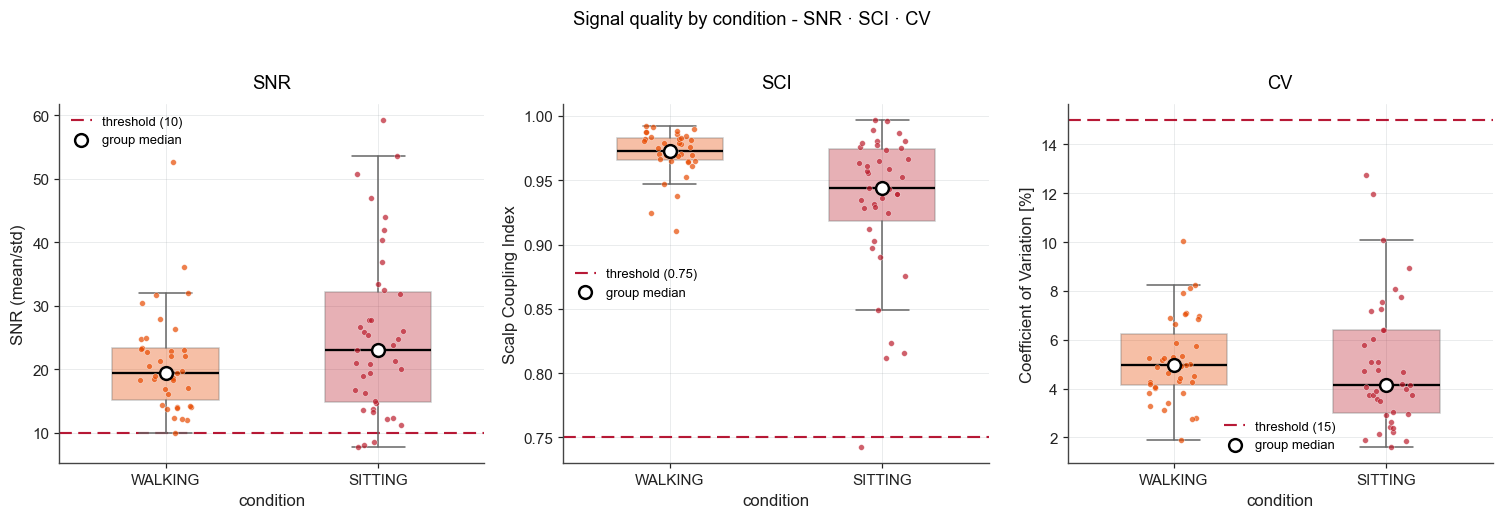

In [8]:
# participant medians (and means) per condition; white circle = group median.
# The median panel is shown below; every figure is saved to figs/quality/.
THRESHOLDS = {"snr": 10.0, "sci": 0.75, "cv": 15.0}
QUALITY_FIGS = FIG_DIR / "quality"; QUALITY_FIGS.mkdir(exist_ok=True)


def add_group_median(ax, df, metric):
    """Replace the group-mean diamonds (zorder 5 in plot_quality_by_condition)
    with the group median per condition."""
    for coll in [c for c in ax.collections if c.get_zorder() == 5]:
        coll.remove()
    for i, c in enumerate(CONDITION_ORDER):
        med = float(df.loc[df.condition == c, metric].dropna().median())
        ax.scatter(i + 1, med, marker="o", s=70, facecolor="white", edgecolor="black",
                   linewidth=1.6, zorder=6, label="group median" if i == 0 else None)
    ax.legend(loc="best", fontsize=8.5)


for stat in ("median", "mean"):
    df = pd.DataFrame([{"subject": r.subject, "condition": c,
                        **{m: getattr(r, f"{m}_{stat}_{c}") for m in ("snr", "sci", "cv")}}
                       for r in wide.itertuples(index=False) for c in ("SITTING", "WALKING")])
    df.attrs["thresholds"] = THRESHOLDS

    figs = qm.plot_quality_report(df, metrics=("snr", "sci", "cv"), agg="observation",
                                  order=CONDITION_ORDER, clip_outliers=False)
    for metric, (fig, ax) in figs.items():
        add_group_median(ax, df, metric)
        ax.set_title(f"{qm._METRIC_LABELS[metric]} by condition, participant {stat}s")
        fig.savefig(QUALITY_FIGS / f"{metric}_{stat}.png",
                    dpi=300, bbox_inches="tight")
        plt.close(fig)

    fig, axes = qm.plot_quality_panel(df, metrics=("snr", "sci", "cv"), agg="observation",
                                      order=CONDITION_ORDER, clip_outliers=False,
                                      suptitle="Signal quality by condition")
    for ax, metric in zip(axes, ("snr", "sci", "cv")):
        add_group_median(ax, df, metric)
    fig.savefig(QUALITY_FIGS / f"panel_{stat}.png",
                dpi=300, bbox_inches="tight")
    if stat != "median":
        plt.close(fig)
plt.show()

---
# ROI responses: FPA

Brodmann ROI, both hemispheres: FPA = BA10. MC vs REST per condition.

In [9]:
# Brodmann areas on the reconstruction and the ROI members
example = next(iter(all_results.values()))["img_brain_bl"]
present = available_parcels_from_image(example)
print(f"{len(present)} Brodmann areas on the cortical surface.")
for name in ROIS:
    print(f"  {name} (BA {BRODMANN_ROIS[name]}): {select_roi_parcels(present, name)}")

86 Brodmann areas on the cortical surface.
  FPA (BA [10]): ['left_BA10', 'right_BA10']


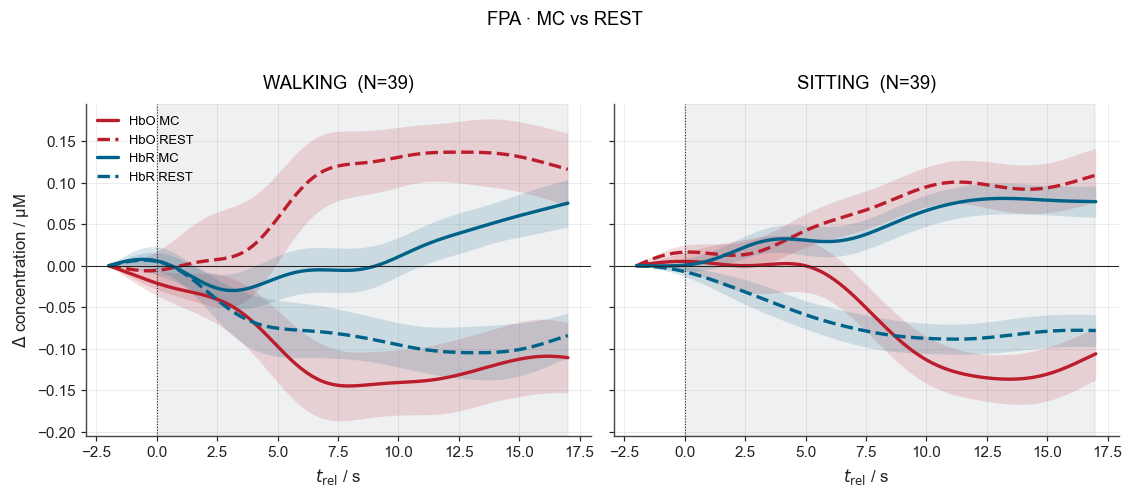

In [10]:
# time courses, mean ± SEM across subjects, per condition
for name in ROIS:
    fig, _ = roi.plot_roi_averaged(all_results, name, conditions=CONDITION_ORDER,
                                   window=RESP_WINDOW)
    fig.savefig(FIG_DIR / f"{name}_averaged.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
# window means: one row per subject × ROI × chromophore × trial type
roi_df = roi.build_group_roi_table(
    all_results, rois=ROIS,
    before=RESP_WINDOW[0], after=RESP_WINDOW[1],
    output_path=RESULTS_DIR / "group_roi_window.csv",
)
display(roi_df.head(8))

[roi] group ROI table: 312 rows -> results\group_roi_window.csv


,run_id,subject,condition,roi,hemisphere,n_vertices,chromo,trial_type,mean,peak,time_to_peak
0,sub-01_ses-1_task-SITTING_nirs,01,SITTING,FPA,both,724,HbO,MC,-0.166464,-0.235297,10.080
1,sub-01_ses-1_task-SITTING_nirs,01,SITTING,FPA,both,724,HbO,REST,0.071409,0.177857,16.485
2,sub-01_ses-1_task-SITTING_nirs,01,SITTING,FPA,both,724,HbR,MC,0.105976,0.155350,16.905
3,sub-01_ses-1_task-SITTING_nirs,01,SITTING,FPA,both,724,HbR,REST,-0.091693,-0.148141,16.905
4,sub-01_ses-1_task-WALKING_nirs,01,WALKING,FPA,both,724,HbO,MC,-0.142943,-0.222164,12.600
5,sub-01_ses-1_task-WALKING_nirs,01,WALKING,FPA,both,724,HbO,REST,0.106080,0.173687,15.540
6,sub-01_ses-1_task-WALKING_nirs,01,WALKING,FPA,both,724,HbR,MC,0.016371,0.075253,16.905
7,sub-01_ses-1_task-WALKING_nirs,01,WALKING,FPA,both,724,HbR,REST,-0.019274,-0.073005,16.905


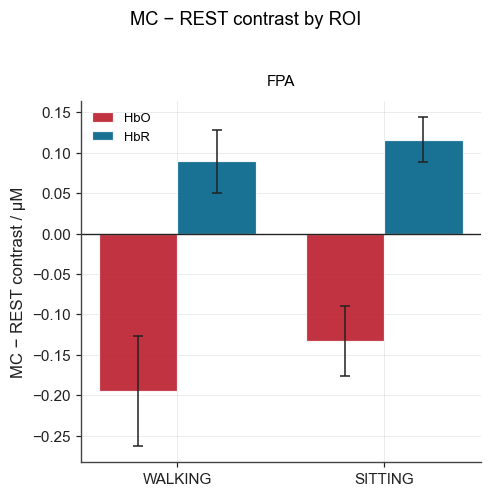

In [12]:
# MC − REST per ROI × chromophore × condition (mean ± SEM)
fig, _ = roi.plot_roi_contrast_bars(roi_df, rois=ROIS, order=CONDITION_ORDER)
fig.savefig(FIG_DIR / "roi_contrast_bars.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Effect maps (3D)

Group-mean concentration change averaged over `RESP_WINDOW` (the window of the ROI
means).

In [13]:
CAM3D = (-45, 25, 380)   # azimuth, elevation, distance
VIEWS = ("oblique",)

# MC and REST separately
for chromo in ("HbO", "HbR"):
    for tt in ("MC", "REST"):
        plot_window_average_map(
            all_results, head_ijk,
            window=RESP_WINDOW, chromo=chromo, trial_type=tt,
            views=VIEWS, camera=CAM3D,
            filename=FIG_DIR / f"effect_{chromo}_{tt}",
        )

C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · MC · 0–17 s (N=78) | clim=(-0.152, 0.152) µM
[effect3d] saved figs\effect_HbO_MC.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · REST · 0–17 s (N=78) | clim=(-0.13, 0.13) µM
[effect3d] saved figs\effect_HbO_REST.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbR · MC · 0–17 s (N=78) | clim=(-0.0967, 0.0967) µM
[effect3d] saved figs\effect_HbR_MC.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbR · REST · 0–17 s (N=78) | clim=(-0.117, 0.117) µM
[effect3d] saved figs\effect_HbR_REST.png


In [14]:
# MC − REST
for chromo in ("HbO", "HbR"):
    plot_window_average_map(
        all_results, head_ijk,
        window=RESP_WINDOW, chromo=chromo, contrast=("MC", "REST"),
        views=VIEWS, camera=CAM3D,
        filename=FIG_DIR / f"effect_{chromo}_MC_minus_REST",
    )

C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · MC − REST · 0–17 s (N=78) | clim=(-0.273, 0.273) µM
[effect3d] saved figs\effect_HbO_MC_minus_REST.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbR · MC − REST · 0–17 s (N=78) | clim=(-0.199, 0.199) µM
[effect3d] saved figs\effect_HbR_MC_minus_REST.png


In [15]:
# MC − REST per condition
for cond in CONDITION_ORDER:
    plot_window_average_map(
        all_results, head_ijk,
        window=RESP_WINDOW, chromo="HbO", contrast=("MC", "REST"),
        condition=cond, views=("oblique", "left", "frontal"), camera=CAM3D,
        filename=FIG_DIR / f"effect_HbO_MC_minus_REST_{cond}",
    )

C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · MC − REST · WALKING · 0–17 s (N=39) | clim=(-0.364, 0.364) µM
[effect3d] saved figs\effect_HbO_MC_minus_REST_WALKING.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · MC − REST · SITTING · 0–17 s (N=39) | clim=(-0.243, 0.243) µM
[effect3d] saved figs\effect_HbO_MC_minus_REST_SITTING.png


### Condition × trial-type maps with ROI outlines

HbO/HbR × SITTING/WALKING × MC/REST, averaged over `RESP_WINDOW`, four views; FPA
outlined. One colour scale per chromophore, shared by its four maps.

In [16]:
ROI_OUTLINES = [
    ("FPA", "both", "#E84A00", "FPA"),
]
VIEWS_4 = ("oblique", "left", "right", "frontal")

# colour limit per chromophore: max over the four maps of each map's 99th
# percentile of |value|, so no map is clipped harder than the others
def shared_clim(chromo, percentile=99.0):
    per_map = []
    for cond in CONDITION_ORDER:
        avg, _ = window_average_image(all_results, window=RESP_WINDOW,
                                      condition=cond)
        a = avg.sel(chromo=chromo)
        brain = np.asarray(a.is_brain.values, dtype=bool)
        for tt in ("MC", "REST"):
            v = np.asarray(a.sel(trial_type=tt).values, float)[brain]
            per_map.append(np.nanpercentile(np.abs(v), percentile))
    scl = float(np.nanmax(per_map))
    return (-scl, scl)

CLIM = {c: shared_clim(c) for c in ("HbO", "HbR")}
for c, v in CLIM.items():
    print(f"{c}: shared colour scale = ({v[0]:+.4f}, {v[1]:+.4f}) µM")

HbO: shared colour scale = (-0.2176, +0.2176) µM
HbR: shared colour scale = (-0.1542, +0.1542) µM


In [17]:
# all eight maps
for chromo in ("HbO", "HbR"):
    for cond in CONDITION_ORDER:
        for tt in ("MC", "REST"):
            plot_window_average_map(
                all_results, head_ijk,
                window=RESP_WINDOW, chromo=chromo, trial_type=tt,
                condition=cond, views=VIEWS_4, camera=CAM3D,
                clim=CLIM[chromo],
                roi_outlines=ROI_OUTLINES, head_labeled=head_brod,
                filename=FIG_DIR / f"effect_{chromo}_{tt}_{cond}",
            )

C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · MC · WALKING · 0–17 s (N=39) | clim=(-0.218, 0.218) µM
[effect3d] saved figs\effect_HbO_MC_WALKING.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · REST · WALKING · 0–17 s (N=39) | clim=(-0.218, 0.218) µM
[effect3d] saved figs\effect_HbO_REST_WALKING.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbO · MC · SITTING · 0–17 s (N=39) | clim=(-0.218, 0.218) µM
[effect3d] saved figs\effect_HbO_MC_SITTING.png


... (6 outputs left out)

C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbR · MC · SITTING · 0–17 s (N=39) | clim=(-0.154, 0.154) µM
[effect3d] saved figs\effect_HbR_MC_SITTING.png


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[effect3d] HbR · REST · SITTING · 0–17 s (N=39) | clim=(-0.154, 0.154) µM
[effect3d] saved figs\effect_HbR_REST_SITTING.png


---
## Appendix · Cortical activation maps

Group-average HbO maps per condition (PyVista; slow).

In [18]:
RENDER_BRAIN_MAPS = True
if RENDER_BRAIN_MAPS:
    for cond in CONDITION_ORDER:
        subset = {k: v for k, v in all_results.items() if v.get("condition") == cond}
        if not subset:
            continue
        plot_group_brain_map(
            subset, trial_type="MC", view_positions=("left", "right", "top"),
            scalar_bar_title=f"MC HbO — {cond} [µM]", tag=cond,
            out_dir=str(FIG_DIR), trial_types=("MC", "REST"),
        )

[group plot] auto clim = (-0.215, 0.215)


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[gif] saved → figs\group_WALKING_N39_MC_hbo_brain.gif  (39 frames @ 6 fps)
[group plot] WALKING: N=39, saved → figs\group_WALKING_N39_MC_hbo_brain.gif
[group plot] auto clim = (-0.15, 0.15)


C:\VS code\Diffuse-Optical-Tomography-Dataset-Under-Cognitive-Motor-Dual-Task-Interference\.venv\Lib\site-packages\xarray\core\variable.py:315: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  data = np.asarray(data)


[gif] saved → figs\group_SITTING_N39_MC_hbo_brain.gif  (39 frames @ 6 fps)
[group plot] SITTING: N=39, saved → figs\group_SITTING_N39_MC_hbo_brain.gif
